# Building machine learning model for precting oral malodour based on microbiome data
In this exercise, students will build a machine learning model for predicting oral malodour based on microbiome data (Nakano et. al., 2015). The procedures can be served as a beginner's guide that introduces the basics of using python libary scikit-learn to perform machine learning analysis. 

## Computer setup 
The Jupyter Notebook and Python libraries (NumPy, Pandas, scikit-learn) installation see the supplemental material 1.

## Preparation of microbiome datasets
Micorbiome datasets, such as bacterial taxa and operational taxonomic units (OTUs), can be obtained through 16S rRNA amplicon sequencing approaches, followed by corresponding bioinformatics analyses. The csv (comma-separated values) file of OTU table was obtained from the association study of salivary microbiota and oral malodour disease (Nakano et. al., 2015), which can be downloaded from the paper's additional file1, and renamed as otu_table.csv here. As shown below, the first column represents the sample names, and the second column represents the phenotypes (Malodour) to be classified. Column 3 and beyond represents the relative abundance of different OTUs corresponding to different samples in different rows.

In [28]:
# Load the microbiome dataset
# the dataset in the csv format is loaded using the function read_csv() of pandas.
import numpy as np
import pandas as pd

data = pd.read_csv('otu_table.csv', sep=",", encoding="utf-8")
print('The shape of our data is:', data.shape)
data.head(5)

The shape of our data is: (90, 110)


,Samples,Malodour,Cluster_3,Cluster_13,Cluster_14,Cluster_15,Cluster_16,Cluster_17,Cluster_18,Cluster_19,...,Cluster_3715,Cluster_3726,Cluster_3731,Cluster_3732,Cluster_3746,Cluster_3751,Cluster_3769,Cluster_3792,Cluster_3818,Cluster_3838
0,Ig9373,N,10,166,87,328,4,45,526,71,...,2,0,2,0,0,3,0,0,0,0
1,Ig9374,N,15,350,237,33,1,0,519,37,...,1,0,0,0,1,0,0,0,0,0
2,Ig9375,N,24,112,168,62,102,0,547,150,...,5,0,0,11,65,9,0,7,0,7
3,Ig9376,N,27,195,117,59,102,20,882,139,...,5,0,0,3,63,18,5,9,0,1
4,Ig9377,N,48,167,222,18,0,2,544,79,...,2,0,0,6,26,22,3,0,0,0


In [23]:
# Split the data into features (X) and labels (y)
X = data.drop(['Samples', 'Malodour'], axis=1)
y = data['Malodour']
print(X.shape)
print(y.shape)
print(y.head(5))

(90, 108)
(90,)
0    N
1    N
2    N
3    N
4    N
Name: Malodour, dtype: object


In [24]:
# Split the data into training and testing sets
# The microbiome features and their corresponding labels are randomly split to 
# training set (80%) and testing set (20%).
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)


Training set size: (72, 108)
Testing set size: (18, 108)


In [25]:
# Build a random forest (RF) classifier
# The RF classifier is trained on the training sets with "X_train" representing the microbiome features, 
# and "y_train" representing their labels (e.g., N, P).
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()
model.fit(X_train, y_train)


RandomForestClassifier()

In [26]:
# Make a prediction with the testing set
# The trained RF model is tested on the testing set "X_test", and the predicted labels "y_test_predict"
#  are compared with their actual labels "y_test" to calculate an accuracy value.
from sklearn.metrics import accuracy_score
y_test_pred = model.predict(X_test)
y_test_accuracy = accuracy_score(y_test, y_test_pred)
print("Accuracy:", y_test_accuracy)

Accuracy: 0.9444444444444444


> What is the model performance metrics, such as accuracy, specificity, precision, sensitivity(recall)   
  and AUC-ROC(area under the receiver operating characteristic curve)?

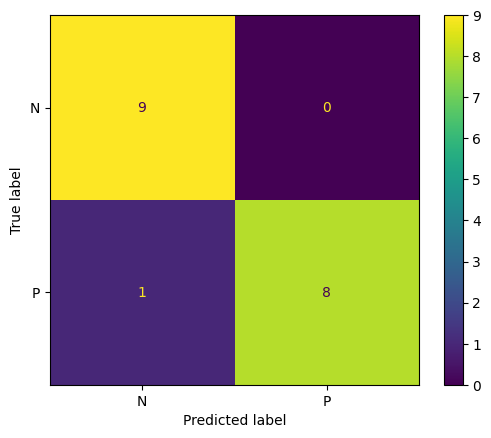

In [ ]:
# Evaluate the model's performance by confusion matrix
# An example confusion matrix is shown in figure 1 and indicated that one samples's 
# phenotype ("P") is wrongly predicted to be "N". 
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_test_pred,  labels = model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels = model.classes_)
disp.plot()

> Please explain what confusion matrix is and how it can be used to evaluate the performance of a model.

## Model optimazition
The Random Forest model with default parameters is presented in this study. The performance of the RF model can be further improved by tuning various hyperparameters of the Random Forest classifier (https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html). In addition, the grid search approach(sklearn.model_selection.GridSearchCV) is often used for comprehensively searching optimized hyperparameter values for a specific classifier.

In [21]:
# grid search
from sklearn.model_selection import GridSearchCV
searchSpace = {'n_estimators': np.arange(10,200,10), 'max_depth':[2,4,6]}
clf = GridSearchCV(model, searchSpace, scoring='accuracy')
clf.fit(X_train, y_train)
print('Best parameters:', clf.best_params_)
print('Test set score: {:.2f}'.format(clf.score(X_test, y_test)))


Best parameters: {'max_depth': 2, 'n_estimators': np.int64(110)}
Test set score: 0.89


> What is the hyperparameters of random forest algorithm: n_estimators, max_depth and min_samples_leaf?


### References
Nakano, Y., Suzuki, N., Kuwata, F., 2018. Predicting oral malodour based on the microbiota in saliva samples using a deep learning approach. BMC Oral Health 18, 128. https://doi.org/10.1186/s12903-018-0591-6
